# Lab 1 — Intro to Behavioral TV Data
**KM-41 Ivannikov Vadym**

## Setup

In [19]:
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")  # Colab and Kaggle
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

### Setup: clean types, decode attribute codes, build helpers

In [20]:
# --- timestamps (drop timezone, keep US Eastern wall-clock time) and dates
for df in (programs, viewings):
    for c in ("start_ts", "end_ts"):
        df[c] = pd.to_datetime(df[c])
        if df[c].dt.tz is not None:
            df[c] = df[c].dt.tz_localize(None)
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"]).dt.normalize()
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"]).dt.normalize()

# --- session length and broadcast day (06:00-05:59) of every session
viewings["minutes"] = (viewings.end_ts - viewings.start_ts).dt.total_seconds() / 60
viewings["broadcast_date"] = (viewings.start_ts - pd.Timedelta(hours=6)).dt.normalize()
viewings["household"] = viewings.respondent_id // 100

# --- codes joined to their names
va = viewer_attributes.merge(
    attributes[["attr_id", "attr_group", "attr_name", "value_type"]], on="attr_id", how="left"
)
print("Decoded attribute table (sample):")
display(va.sample(8, random_state=0))
print("Attribute groups:")
print(attributes.attr_group.value_counts().to_string())

# --- persons table: sex (201 = Male, 202 = Female) and age in years (code 300)
sex = (viewer_attributes[viewer_attributes.attr_id.isin([201, 202])]
       .drop_duplicates("respondent_id").set_index("respondent_id").attr_id.map({201: "M", 202: "W"}))
age = (viewer_attributes[viewer_attributes.attr_id == 300]
       .drop_duplicates("respondent_id").set_index("respondent_id")["value"])

dw_h = daily_weights[daily_weights.resp_type == "H"]
dw_p = daily_weights[daily_weights.resp_type.isin(["R", "L"])]   # persons = R and L only (no guests)

persons = pd.DataFrame({"sex": sex, "age": age})
persons = persons[persons.index.isin(dw_p.respondent_id.unique())]

# --- monthly weight = average weight over the broadcast days the person was in-tab
w_month = dw_p.groupby("respondent_id").weight.mean()

# --- audiences (target groups)
AUD = {
    "P2+":    lambda p: p.age >= 2,
    "A18-34": lambda p: p.age.between(18, 34),
    "A18-49": lambda p: p.age.between(18, 49),
    "M18-34": lambda p: (p.sex == "M") & p.age.between(18, 34),
    "W18-34": lambda p: (p.sex == "W") & p.age.between(18, 34),
    "M35-54": lambda p: (p.sex == "M") & p.age.between(35, 54),
    "W35-54": lambda p: (p.sex == "W") & p.age.between(35, 54),
    "M55+":   lambda p: (p.sex == "M") & (p.age >= 55),
    "W55+":   lambda p: (p.sex == "W") & (p.age >= 55),
}
# P2+ = everybody the panel measures (also people with a missing age)
group_ids = {g: set(persons.index[f(persons)]) for g, f in AUD.items()}
group_ids["P2+"] = set(persons.index)


def wquantile(x, w, q):
    """Weighted quantile: smallest x whose cumulative weight share is >= q."""
    x, w = np.asarray(x, float), np.asarray(w, float)
    o = np.argsort(x, kind="stable")
    x, w = x[o], w[o]
    c = np.cumsum(w)
    return x[np.searchsorted(c, q * c[-1])]


# viewings split by network for fast telecast matching
vw_by_net = {n: g for n, g in viewings.groupby("network_code")}


def watchers(tc, rtypes):
    """respondent_ids with >= 1 minute of overlap with telecast `tc` (a programs row)."""
    v = vw_by_net[tc.network_code]
    v = v[v.resp_type.isin(rtypes) & (v.start_ts < tc.end_ts) & (v.end_ts > tc.start_ts)]
    ov = (v.end_ts.clip(upper=tc.end_ts) - v.start_ts.clip(lower=tc.start_ts)).dt.total_seconds()
    return set(v.respondent_id[ov >= 60])


def day_rating(tc, rtypes, ids_filter=None):
    """(rating %, projected audience in M) of a telecast for H or for persons (optionally one audience)."""
    base = dw_h if rtypes == ["H"] else dw_p
    day = base[base.broadcast_date == tc.broadcast_date].set_index("respondent_id").weight
    if ids_filter is not None:
        day = day[day.index.isin(ids_filter)]
    seen = watchers(tc, rtypes)
    w_seen = day[day.index.isin(seen)].sum()
    return 100 * w_seen / day.sum(), w_seen / 1e6

Decoded attribute table (sample):


,respondent_id,attr_id,value,attr_group,attr_name,value_type
15437,10063003,300,15.0,Age,Age in years,numeric
51488,10208001,601,NaN,Employment (18+),Working full time (30+ h/week),flag
62160,10252802,365,NaN,Age band,65+,flag
54837,10222002,504,NaN,Education (18+),Bachelor's degree or higher,flag
26585,10107902,101,NaN,Respondent type,R: panel member (household member),flag
69249,10282800,852,NaN,County size,B: large,flag
80693,10329903,101,NaN,Respondent type,R: panel member (household member),flag
25193,10102802,202,NaN,Sex,Female,flag


Attribute groups:
attr_group
Age band                 10
Household income          6
TV reception              6
Race / ethnicity          5
Household size            5
Respondent type           4
Education (18+)           4
Census region             4
County size               4
Employment (18+)          3
Sex                       2
Household role            2
Children in household     2
Age                       1


## Task 1.1 — Panel and universe

In [21]:
n_hh = dw_h.respondent_id.nunique()
n_pe = dw_p.respondent_id.nunique()
per_day_h = dw_h.groupby("broadcast_date").agg(n=("weight", "size"), w=("weight", "sum"))
per_day_p = dw_p.groupby("broadcast_date").agg(n=("weight", "size"), w=("weight", "sum"))

print("Telecasts:", programs.telecast_id.nunique())
print("Programs:", programs.program_name.nunique())
print("Networks:", programs.network_code.nunique())
print("Households in panel:", n_hh)
print("Persons in panel:", n_pe)
print("Households in-tab, average day:", round(per_day_h.n.mean(), 1))
print("Persons in-tab, average day:", round(per_day_p.n.mean(), 1))
print("US TV households represented, average day (M):", f"{per_day_h.w.mean() / 1e6:.2f}")
print("US persons represented, average day (M):", f"{per_day_p.w.mean() / 1e6:.2f}")

# why does viewer_attributes list more?
type_code = viewer_attributes[viewer_attributes.attr_id.isin([101, 102, 104])].drop_duplicates("respondent_id")
in_tab_ids = set(daily_weights.respondent_id)
never = type_code[~type_code.respondent_id.isin(in_tab_ids)]
print("\nRecords in viewer_attributes:", type_code.respondent_id.nunique(),
      "| never in-tab in October:", len(never))
print(never.attr_id.map({101: "members (R)", 102: "long-term visitors (L)", 104: "households (H)"})
      .value_counts().to_string())

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28

Records in viewer_attributes: 14472 | never in-tab in October: 8
attr_id
members (R)       6
households (H)    2


**viewer_attributes** includes all 14,472 panel records, while **daily_weights** covers only those measured in October: 4,254 households and 10,210 people. Eight records had no October weights, possibly because they left or joined the panel or had meter issues. On an average day, about 91% of the panel is measured. Weights are adjusted daily so the sample represents the full US population: 125.8 million TV households and 317.3 million people aged 2+.

## Task 1.2 — Average audience by hour of day

Broadcast days: {'weekday': 23, 'weekend': 8}


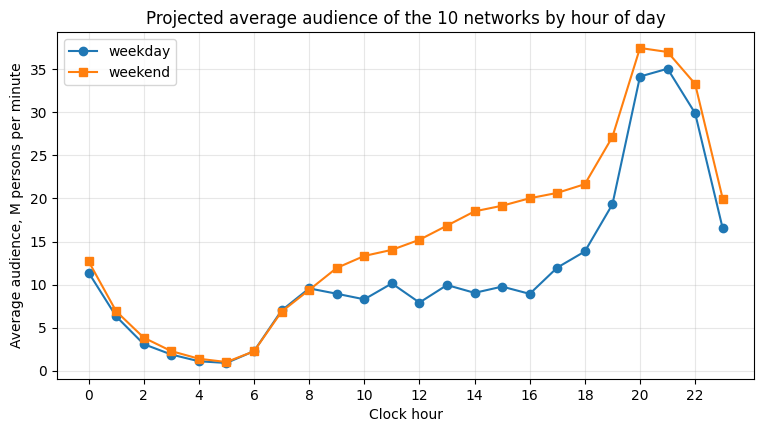

Peak hour, weekdays: 21
Peak hour, weekends: 20
hour        0     1     2     3     4     5     6     7     8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
daytype                                                                                                                                                                
weekday  11.39  6.30  3.08  1.87  1.09  0.89  2.26  6.99  9.55   8.93   8.28  10.13   7.91   9.94   9.03   9.76   8.92  11.97  13.84  19.32  34.17  35.08  29.91  16.52
weekend  12.69  6.89  3.83  2.27  1.38  1.00  2.25  6.86  9.37  11.93  13.33  14.03  15.20  16.85  18.51  19.16  20.03  20.65  21.66  27.16  37.49  37.02  33.31  19.99


In [22]:
vp = viewings[viewings.resp_type.isin(["R", "L"])].copy()


def split_by_hour(df):
    """Split sessions at hour boundaries -> rows (hour_start, minutes, weight)."""
    s, e = df.start_ts, df.end_ts
    h0 = s.dt.floor("h")
    n_max = int(np.ceil(((e - h0).dt.total_seconds() / 3600).max()))
    out = []
    for k in range(n_max):
        hs = h0 + pd.Timedelta(hours=k)
        he = hs + pd.Timedelta(hours=1)
        a = s.where(s > hs, hs)
        b = e.where(e < he, he)
        m = (b - a).dt.total_seconds() / 60
        ok = m > 0
        out.append(pd.DataFrame({"hour_start": hs[ok], "minutes": m[ok], "weight": df.weight[ok]}))
    return pd.concat(out, ignore_index=True)


hm = split_by_hour(vp)
hm["bday"] = (hm.hour_start - pd.Timedelta(hours=6)).dt.normalize()   # broadcast day of the minutes
hm = hm[hm.bday.isin(daily_weights.broadcast_date.unique())]          # keep October broadcast days
hm["daytype"] = np.where(hm.bday.dt.dayofweek >= 5, "weekend", "weekday")
hm["hour"] = hm.hour_start.dt.hour
hm["wmin"] = hm.minutes * hm.weight

bdays = pd.Series(sorted(daily_weights.broadcast_date.unique()))
n_days = pd.Series(np.where(bdays.dt.dayofweek >= 5, "weekend", "weekday")).value_counts()
print("Broadcast days:", n_days.to_dict())

aud = (hm.groupby(["hour", "daytype"]).wmin.sum().unstack("daytype")
       .reindex(range(24)).fillna(0))
aud = aud / 60 / n_days / 1e6          # millions of persons watching per minute, average

fig, ax = plt.subplots(figsize=(9, 4.5))
for col, style in (("weekday", "-o"), ("weekend", "-s")):
    ax.plot(aud.index, aud[col], style, label=col)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Clock hour")
ax.set_ylabel("Average audience, M persons per minute")
ax.set_title("Projected average audience of the 10 networks by hour of day")
ax.grid(alpha=.3)
ax.legend()
plt.show()

print("Peak hour, weekdays:", int(aud.weekday.idxmax()))
print("Peak hour, weekends:", int(aud.weekend.idxmax()))
print(aud.round(2).T.to_string())

The ten networks reach their highest audience during prime time: at 21:00 on weekdays (35.1 M) and 20:00 on weekends (37.5 M). Weekends have much larger daytime audiences, with 13–21 M viewers versus 8–12 M on weekdays, likely because more people are home and watching sports or other programs. The weekend evening peak is about 7% higher and occurs an hour earlier. Early morning and overnight audiences are similar on both day types. Overall, weekends attract more viewers throughout the afternoon, while weekday viewing is more concentrated in prime time.

## Task 1.3 — Session length

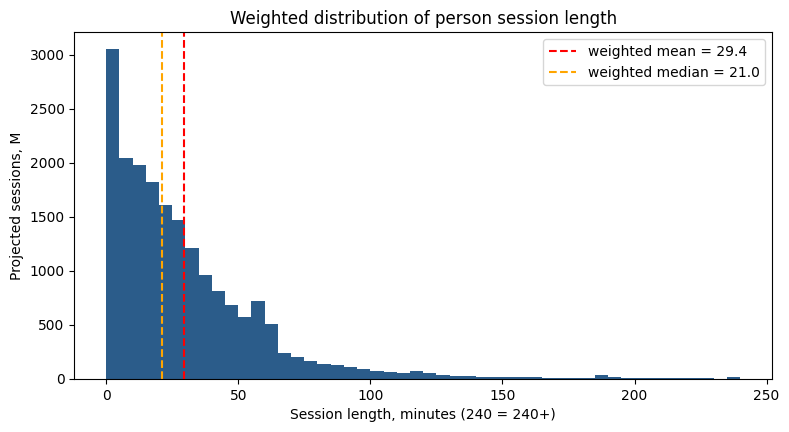

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [23]:
lens = vp[vp.minutes > 0]
mean_len = np.average(lens.minutes, weights=lens.weight)
median_len = wquantile(lens.minutes, lens.weight, 0.5)

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(0, 245, 5)
ax.hist(lens.minutes.clip(upper=240), bins=bins, weights=lens.weight / 1e6, color="#2b5c8a")
ax.axvline(mean_len, color="red", ls="--", label=f"weighted mean = {mean_len:.1f}")
ax.axvline(median_len, color="orange", ls="--", label=f"weighted median = {median_len:.1f}")
ax.set_xlabel("Session length, minutes (240 = 240+)")
ax.set_ylabel("Projected sessions, M")
ax.set_title("Weighted distribution of person session length")
ax.legend()
plt.show()

print("Session length, weighted mean (min):", round(mean_len, 1))
print("Session length, weighted median (min):", round(median_len, 1))

The weighted mean session is 29.4 min and the weighted median is 21.0 min. The distribution is
strongly right-skewed: the most common sessions are very short (the tallest bar is 0-5 minutes, i.e.
quick tune-ins and channel surfing), half of all projected sessions are 21 minutes or shorter, and
there is a long thin tail of sessions of 1-4 hours (full programs, movies, live sports, evening
viewing). These few long sessions pull the mean up by about 8 minutes (+40%) above the median, while
the median is not affected by them. For a client deck I would show the **median (21 min)** as the
"typical" session, because it describes what a typical viewing session looks like and is not distorted
by the long tail. The mean is still useful as a separate number for total viewing time
(mean x number of sessions = total minutes), so I would show it only for that purpose, and I would not
say that "a typical viewer watches for 29 minutes".

## Task 2 — Program reach curve

network_code  program_name    
CBS           CBS Evening News    23
dtype: int64


,telecast_id,date,hh_rating,p2_rating,audience_M
0,1003837,2024-10-01,3.47,1.67,5.28
1,1003857,2024-10-02,3.07,1.48,4.68
2,1003877,2024-10-03,2.99,1.47,4.68
3,1003896,2024-10-04,3.00,1.51,4.81
4,1003936,2024-10-07,3.06,1.52,4.83
5,1003952,2024-10-08,3.17,1.57,4.97
6,1003970,2024-10-09,2.98,1.48,4.70
7,1003985,2024-10-10,3.38,1.62,5.13
8,1004001,2024-10-11,3.09,1.48,4.69
9,1004040,2024-10-14,2.93,1.45,4.59


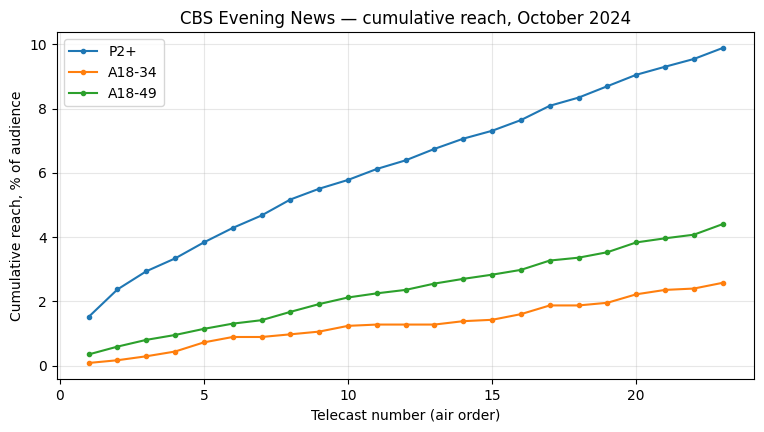

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [24]:
print(programs[programs.program_name.str.contains("Evening News", case=False)]
      .groupby(["network_code", "program_name"]).size())

cbs = programs[(programs.network_code == "CBS")
               & (programs.program_name == "CBS Evening News")
               & (programs.start_ts.dt.dayofweek < 5)].sort_values("start_ts")

rows = []
for tc in cbs.itertuples():
    hh_r, _ = day_rating(tc, ["H"])
    p_r, p_aud = day_rating(tc, ["R", "L"])
    rows.append({"telecast_id": tc.telecast_id, "date": tc.broadcast_date.date(),
                 "hh_rating": hh_r, "p2_rating": p_r, "audience_M": p_aud})
tab2 = pd.DataFrame(rows)
display(tab2.round(2))

# cumulative reach in air order (monthly weights)
seen = set()
reach = {g: [] for g in ("P2+", "A18-34", "A18-49")}
for tc in cbs.itertuples():
    seen |= watchers(tc, ["R", "L"])
    for g in reach:
        ids = group_ids[g]
        reach[g].append(100 * w_month[list(seen & ids)].sum() / w_month[list(ids)].sum())

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(1, len(cbs) + 1)
for g, ys in reach.items():
    ax.plot(x, ys, "-o", ms=3, label=g)
ax.set_xlabel("Telecast number (air order)")
ax.set_ylabel("Cumulative reach, % of audience")
ax.set_title("CBS Evening News — cumulative reach, October 2024")
ax.grid(alpha=.3)
ax.legend()
plt.show()

print("Telecasts of the program:", len(cbs))
print("Average household rating (%):", f"{tab2.hh_rating.mean():.1f}")
print("Average P2+ rating (%):", f"{tab2.p2_rating.mean():.1f}")
print("Average projected audience (M):", f"{tab2.audience_M.mean():.2f}")
print("Final reach P2+ (%):", f"{reach['P2+'][-1]:.1f}")
print("Final reach A18-34 (%):", f"{reach['A18-34'][-1]:.1f}")
print("Final reach A18-49 (%):", f"{reach['A18-49'][-1]:.1f}")

A rating measures the audience of a single telecast, averaging 1.6% (about 4.9 million viewers), while reach counts everyone who watched at least one of the 23 telecasts. Ratings stay fairly stable, but cumulative reach grows to 9.9% as new occasional viewers join the regular audience. Since reach is only about six times the single-telecast rating, many viewers watch repeatedly. The program reaches P2+ viewers best (9.9%), followed by A18–49 (4.4%) and A18–34 (2.6%). This suggests that evening news attracts mainly older viewers and is less effective for reaching young adults.

## Task 3 — Program frequency

Young and the Restless telecasts in October: 23


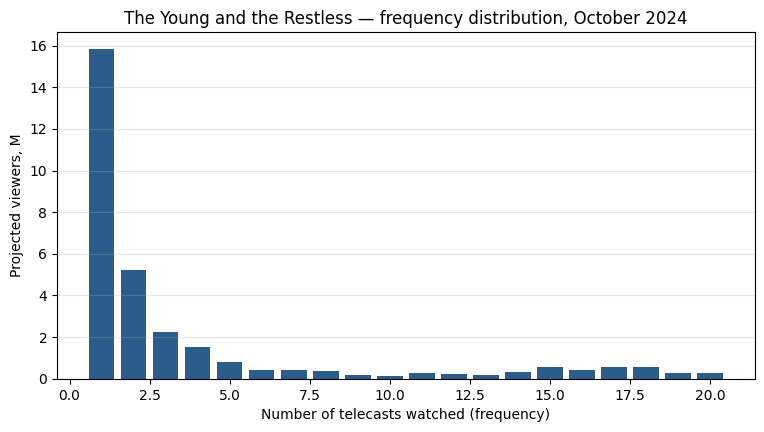

Projected viewers (M): 30.80
Average frequency (weighted): 3.63
Median frequency (weighted): 1.00
Share of views from the most loyal viewers: 0.704
(weighted 80th percentile of frequency = 4; loyal = frequency >= 4)


In [25]:
yr = programs[(programs.network_code == "CBS")
              & programs.program_name.str.contains("Young and the Restless", case=False)].sort_values("start_ts")
print("Young and the Restless telecasts in October:", len(yr))

freq = pd.Series(0, index=w_month.index)
for tc in yr.itertuples():
    ids = [i for i in watchers(tc, ["R", "L"]) if i in freq.index]
    freq.loc[ids] += 1

viewers = freq[freq > 0]
w = w_month[viewers.index]

avg_f = np.average(viewers, weights=w)
med_f = wquantile(viewers, w, 0.5)
p80 = wquantile(viewers, w, 0.8)
loyal = viewers >= p80
share_loyal = (w * viewers)[loyal].sum() / (w * viewers).sum()

dist = w.groupby(viewers).sum() / 1e6
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(dist.index, dist.values, color="#2b5c8a")
ax.set_xlabel("Number of telecasts watched (frequency)")
ax.set_ylabel("Projected viewers, M")
ax.set_title("The Young and the Restless — frequency distribution, October 2024")
ax.grid(axis="y", alpha=.3)
plt.show()

print("Projected viewers (M):", f"{w.sum() / 1e6:.2f}")
print("Average frequency (weighted):", f"{avg_f:.2f}")
print("Median frequency (weighted):", f"{med_f:.2f}")
print("Share of views from the most loyal viewers:", f"{share_loyal:.3f}")
print(f"(weighted 80th percentile of frequency = {p80:.0f}; loyal = frequency >= {p80:.0f})")

30.8 M people watched at least one of the 23 telecasts, but the typical viewer watched very few of them: the weighted median frequency is 1, i.e. at least half of the viewers saw only ONE telecast (the first bar, about 16 M viewers, is by far the tallest), and the next bar (2 telecasts) is only about 5 M. At the other end there is a small but clearly visible second group of near-daily viewers (15-20 telecasts), the loyal core of the soap. The weighted average frequency is 3.63, which is more than three times the median. The 80th percentile of the frequency is 4, so the "most loyal viewers" are those who watched 4 or more telecasts: roughly a fifth of the viewers, but they generate 70.4% of all views. So the average is not a fair summary: it is pulled up by the heavy viewers and describes almost nobody: a typical viewer watched once, a loyal viewer watched 15+ times, and nobody is "around 3.6". It is a case where the average can lie. For a client I would show the distribution (or the median together with the share of views from the loyal viewers): the audience is a small, very loyal core plus a large group of occasional viewers, which matters for planning frequency and reach.

## Task 4 — Networks by age and gender

In [26]:
vq = vp.join(persons, on="respondent_id", how="inner")
vq = vq[vq.age.notna() & (vq.minutes > 0)].copy()
vq["pmin"] = vq.minutes * vq.weight

SIX = ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]
top5 = {}
for g in SIX:
    sub = vq[AUD[g](vq)]
    top5[g] = (sub.groupby("network_code").pmin.sum() / 1e6).sort_values(ascending=False).head(5)
top5_tab = pd.DataFrame(
    {g: [f"{n} ({v:,.1f})" for n, v in s.items()] for g, s in top5.items()},
    index=range(1, 6))
top5_tab.index.name = "rank"
print("Top 5 networks by projected minutes (millions):")
display(top5_tab)

vq["young"] = vq.age.between(18, 34)
share_w = vq.groupby("network_code").apply(lambda d: d.pmin[d.young].sum() / d.pmin.sum())
share_r = vq.groupby("network_code").apply(lambda d: d.minutes[d.young].sum() / d.minutes.sum())
share_tab = pd.DataFrame({"share_18_34_weighted": share_w, "share_18_34_raw": share_r}).sort_values(
    "share_18_34_weighted", ascending=False)
display(share_tab.round(3))

young_abs = vq[vq.young].groupby("network_code").pmin.sum().div(1e6).sort_values(ascending=False)
print("Projected 18-34 minutes (M) by network:")
print(young_abs.round(1).to_string())

print("Youngest network:", share_w.idxmax(), f"({share_w.max():.3f})")
print("Oldest network:", share_w.idxmin(), f"({share_w.min():.3f})")

Top 5 networks by projected minutes (millions):


,M18-34,W18-34,M35-54,W35-54,M55+,W55+
rank,,,,,,
1,"FOX (4,386.6)","FOX (4,574.4)","FOX (12,804.7)","NBC (11,639.1)","CBS (38,274.0)","CBS (47,120.3)"
2,"NBC (3,910.4)","NBC (4,527.6)","NBC (10,986.7)","FOX (11,161.4)","NBC (34,267.4)","NBC (41,391.9)"
3,"CBS (3,044.3)","ABC (3,504.9)","ABC (9,037.0)","ABC (9,438.6)","FOX (30,878.5)","ABC (38,840.0)"
4,"ABC (3,010.8)","CBS (2,811.2)","CBS (8,134.1)","CBS (8,162.8)","ABC (30,793.3)","FOX (36,914.7)"
5,"FX (1,474.0)","FX (1,383.5)","FX (2,370.8)","HGTV (3,051.8)","FNC (27,903.7)","FNC (31,450.7)"


,share_18_34_weighted,share_18_34_raw
network_code,,
FX,0.266,0.232
BRAVO,0.148,0.127
FOX,0.082,0.075
FOOD,0.078,0.071
NBC,0.073,0.068
ABC,0.064,0.060
HGTV,0.058,0.052
CBS,0.051,0.050
HIST,0.048,0.044


Projected 18-34 minutes (M) by network:
network_code
FOX      8961.1
NBC      8438.0
ABC      6515.6
CBS      5855.6
FX       2857.4
FNC      1156.6
HGTV      938.3
BRAVO     929.2
FOOD      918.7
HIST      484.7
Youngest network: FX (0.266)
Oldest network: FNC (0.018)


After weighting, the share of viewing minutes from adults aged 18–34 increases across all ten networks. FX has the youngest audience, rising from 23.2% raw to 26.6% weighted, while Fox News has the oldest, at 1.8% weighted. The biggest increases occur on younger-skewing networks such as FX (+3.4 percentage points) and Bravo (12.7% to 14.8%), while older-skewing networks like CBS and Fox News show very little change. This happens because weighting adjusts the panel to represent the US population. Since young adults are under-represented in the panel, their viewing receives more weight in the final estimates. Using raw data would underestimate young audiences and could lead advertisers to make poor decisions about network selection and ad pricing. However, audience share is not the same as audience size. Although FX has the highest proportion of young viewers, it ranks only fifth in total projected viewing minutes among adults aged 18–34. Larger broadcast networks such as FOX, NBC, ABC, and CBS can deliver more young viewers because their overall audiences are much bigger.

**Bonus Question:** 
Fox News is the oldest network: only 1.8% of its minutes come from 18-34 viewers, so I would not sell it as a young-adult network. But its audience is large, and in absolute terms it still delivers about 1.16 billion projected 18-34 minutes, more than Bravo, HGTV, Food Network or History. I would pitch it as a volume buy for an advertiser who wants young adults in addition to other audiences: sell it on an A18-34 audience guarantee (the advertiser pays only for the young viewers actually delivered), and use it to add young reach to a main campaign on young-skewing networks like FX. I would be honest that about 98% of the viewing is by older viewers, so it is not efficient if young adults are the only target.